### Make a temporary space in /flash

In [14]:
import os, random, string

In [15]:
cwd = os.path.basename(os.getcwd())
tmpdir = os.path.join("/flash/ReiterU/tmp/", 'tomo_' + ''.join(random.choices(string.ascii_uppercase, k=12)))
print(tmpdir)
if not os.path.exists(tmpdir):
    os.makedirs(tmpdir)

/flash/ReiterU/tmp/tomo_CFHGBAOIAWJY


### Main

In [16]:
from matplotlib import pyplot as plt
import numpy as np
import subprocess

In [17]:
from matplotlib import font_manager
import matplotlib as mpl
font_manager.fontManager.addfont('/bucket/ReiterU/common/fonts/arial.ttf')
mpl.rcParams.update({
    'font.size': 7,
    'axes.titlesize': 7,
    'legend.fontsize': 7,
    'font.family': 'sans-serif',
    'font.sans-serif': "Arial",
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.linewidth': 0.5,
    'xtick.major.width': 0.5,
    'xtick.major.size': 2,
    'xtick.minor.size': 2,
    'xtick.minor.width': 0.5,
    'ytick.major.width': 0.5,
    'ytick.minor.width': 0.5,
    'ytick.major.size': 2,
    'ytick.minor.size': 2,
    'xtick.major.pad': 2,
    'ytick.major.pad': 2,
    'axes.labelpad': 3
})

In [18]:
names = [
    "20240614_rec4",
    "20241018_rec11",
    "20250303_rec7"
]

thetas = []
for n in names:
    d = np.load(f"/bucket/ReiterU/OLdev/analysis/20250416_IGL_waves/{n}/plots/thetas.npy")
    thetas.append(d)
thetas = np.concat(thetas)

speeds = []
for n in names:
    d = np.load(f"/bucket/ReiterU/OLdev/analysis/20250416_IGL_waves/{n}/plots/speeds.npy")
    speeds.append(d)
speeds = np.concat(speeds)

intervals = []
for n in names:
    d = np.load(f"/bucket/ReiterU/OLdev/analysis/20250416_IGL_waves/{n}/plots/intervals.npy")
    intervals.append(d)
intervals = np.concat(intervals)

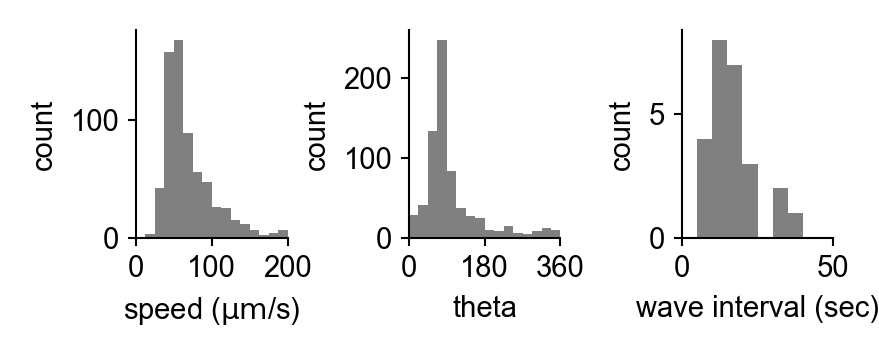

In [19]:
fig = plt.figure(figsize=(3.0,0.9), dpi=300)
gs = fig.add_gridspec(1, 3, width_ratios=[1,1,1], wspace=0.8)

ax = fig.add_subplot(gs[0,0])
count, bin_edges = np.histogram(speeds, range=[0,200], bins=16, density=False)
bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])
ax.bar(bin_centers, count, width=bin_edges[1]-bin_edges[0], lw=0, color="gray")
# ax.axvline(np.median(speeds), lw=1, color="k", ls="--")
ax.set_ylabel("count")
ax.set_xlabel("speed ($\mathrm{\mu m}$/s)")
ax.set_xlim(left=0, right=200)
ax.set_xticks([0, 100, 200])
for sp in ["top", "right"]:
    ax.spines[sp].set_visible(False)

ax = fig.add_subplot(gs[0,1])
count, bin_edges = np.histogram(thetas, range=[0, 360], bins=16, density=False)
bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])
ax.bar(bin_centers, count, width=bin_edges[1]-bin_edges[0], lw=0, color="gray")
# ax.axvline(np.median(thetas), lw=1, color="k", ls="--")
ax.set_xlabel("theta")
ax.set_ylabel("count")
ax.set_xlim([0, 360])
ax.set_xticks([0, 180, 360])
for sp in ["top", "right"]:
    ax.spines[sp].set_visible(False)

ax = fig.add_subplot(gs[0,2])
count, bin_edges = np.histogram(intervals, range=(0,50), bins=10, density=False)
bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])
ax.bar(bin_centers, count, width=bin_edges[1]-bin_edges[0], lw=0, color="gray")
ax.set_xlabel("wave interval (sec)")
ax.set_ylabel("count")
ax.set_xlim([0, 50])
# ax.set_xticks([0, 180, 360])
for sp in ["top", "right"]:
    ax.spines[sp].set_visible(False)

plt.savefig(os.path.join(tmpdir, "distribution.pdf"), bbox_inches='tight')
plt.show()

In [11]:
print(np.median(thetas))
print(np.mean(thetas))

78.27600584116588
100.48552239036333


In [21]:
speeds.max()

np.float64(3757.6409650584055)

In [22]:
print(np.median(speeds))
print(np.mean(speeds[speeds<300]))
print(np.std(speeds[speeds<300]))

59.93991594071707
72.93394816120795
40.67954520650913


### Copy data to bucket

In [13]:
savedir = "/bucket/ReiterU/OLdev/analysis/20250416_IGL_waves"

# cmd1 = f'ssh deigo "mkdir -p {savedir}"'
cmd2 = f'ssh deigo "cp -r {tmpdir}/* {savedir}"'
# print(cmd1)
print(cmd2)

# subprocess.run(cmd1, shell=True, check=True)
subprocess.run(cmd2, shell=True, check=True)

ssh deigo "cp -r /flash/ReiterU/tmp/tomo_HKLUCGNFTPLE/* /bucket/ReiterU/OLdev/analysis/20250416_IGL_waves"


CompletedProcess(args='ssh deigo "cp -r /flash/ReiterU/tmp/tomo_HKLUCGNFTPLE/* /bucket/ReiterU/OLdev/analysis/20250416_IGL_waves"', returncode=0)